# RQ3 — Temperature Sweep: T=0 and T=1.0

**Goal:** Run 100 questions × 3 models × 5 repeats at T=0 and T=1.0  
**New API calls:** ~3,000 (1,500 per temperature)  
**Output:** `rq3_temperature_responses.csv` + `rq3_temperature_metrics.csv`  
**Tip:** Use **GPU runtime** for BERTScore cell  

You already have T=0.7 data in `rq1_metrics_complete.csv` — Cell 5 merges everything.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 1 — Setup + Load Question Bank

In [ ]:
!pip install -q groq mistralai openpyxl

import pandas as pd
import numpy as np
import os, time, csv
from groq import Groq
from mistralai.client import Mistral

# ── Paths ─────────────────────────────────────────────────────────────────────
QB_PATH       = "/content/Question_Bank_Curation.xlsx"   # upload to Colab files
OUT_RESPONSES = "/content/drive/MyDrive/Thesis/rq3_temperature_responses.csv"
T07_METRICS   = "/content/drive/MyDrive/Thesis/rq1_metrics_complete.csv"  # existing T=0.7 data

# ── API Keys ──────────────────────────────────────────────────────────────────
GROQ_KEY    = "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"
MISTRAL_KEY = "b7Zd2n5jSkZVDQHmIunhiHhZuVC78kzi"

groq_client    = Groq(api_key=GROQ_KEY)
mistral_client = Mistral(api_key=MISTRAL_KEY)

# ── Models ────────────────────────────────────────────────────────────────────
MODELS = {
    "llama-3.1-8b": ("groq",    "llama-3.1-8b-instant"),
    "mistral-7b":   ("mistral", "mistral-small-latest"),
}

TEMPERATURES = [0.0, 1.0]   # T=0.7 already done
K_REPEATS    = 5
SYSTEM_PROMPT = "You are a disaster response advisory assistant. Answer the question clearly and concisely based on standard emergency management guidance."

# ── Load question bank ────────────────────────────────────────────────────────
qb = pd.read_excel(QB_PATH, sheet_name="FINAL BANK", header=1)
qb.columns = ["Q_num", "Type", "Scenario", "Question", "Notes"]
qb = qb[qb["Question"].notna() & (qb["Question"].str.strip() != "")].reset_index(drop=True)
qb["Q_id"] = qb["Type"].str[:1] + qb["Q_num"].astype(str).str.zfill(2)

print(f"Questions loaded: {len(qb)}")
print(qb["Type"].value_counts().to_string())
total_calls = len(qb) * len(MODELS) * K_REPEATS * len(TEMPERATURES)
print(f"\nTotal API calls planned: {total_calls} ({len(TEMPERATURES)} temps × {len(qb)} Qs × {len(MODELS)} models × {K_REPEATS} repeats)")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-sdk 1.42.1 requires opentelemetry-api==1.42.1, but you have opentelemetry-api 1.39.1 which is incompatible.
opentelemetry-sdk 1.42.1 requires opentelemetry-semantic-conventions==0.63b1, but you have opentelemetry-semantic-conventions 0.60b1 which is incompatible.
Questions loaded: 100
Type
FACTUAL         25
PROCEDURAL      25
ADVISORY        25
HYPOTHETICAL    25

Total API calls planned: 2000 (2 temps × 100 Qs × 2 models × 5 repeats)


## Cell 2 — API Calls: T=0 and T=1.0  (~45–60 min)
Checkpointed — safe to resume if interrupted.

In [ ]:
import os, time, csv
from groq import Groq
from mistralai.client import Mistral

# ── Make sure directory exists ────────────────────────────────────────────────
os.makedirs(os.path.dirname(OUT_RESPONSES), exist_ok=True)
print(f"Saving to: {OUT_RESPONSES}")

# ── Resume support ────────────────────────────────────────────────────────────
done = set()
if os.path.exists(OUT_RESPONSES):
    try:
        existing = pd.read_csv(OUT_RESPONSES)
        if "Q_id" in existing.columns and len(existing) > 0:
            done = set(zip(existing["Q_id"], existing["model"],
                           existing["temperature"], existing["repeat"]))
            print(f"Resuming — {len(done)} calls already done")
        else:
            os.remove(OUT_RESPONSES)
            print("Stale file removed — starting fresh")
    except Exception:
        os.remove(OUT_RESPONSES)
        print("Corrupt file removed — starting fresh")
else:
    print("Starting fresh")

# ── API functions ─────────────────────────────────────────────────────────────
def call_groq(model_id, question, temperature):
    r = groq_client.chat.completions.create(
        model=model_id,
        messages=[{"role":"system","content":SYSTEM_PROMPT},
                  {"role":"user","content":question}],
        temperature=temperature, max_tokens=512
    )
    return r.choices[0].message.content.strip()

def call_mistral(model_id, question, temperature):
    r = mistral_client.chat.complete(
        model=model_id,
        messages=[{"role":"system","content":SYSTEM_PROMPT},
                  {"role":"user","content":question}],
        temperature=temperature, max_tokens=512
    )
    return r.choices[0].message.content.strip()

def call_model(model_name, question, temperature):
    backend, model_id = MODELS[model_name]
    return call_groq(model_id, question, temperature) if backend == "groq" \
           else call_mistral(model_id, question, temperature)

# ── Test one call before the full run ────────────────────────────────────────
print("\nTesting API connectivity...")
try:
    test = call_model("llama-3.1-8b", "What is a flood?", 0.0)
    print(f"API OK — sample response: {test[:80]}...")
except Exception as e:
    raise RuntimeError(f"API test failed: {e}\nFix API keys before continuing.")

# ── Main loop ─────────────────────────────────────────────────────────────────
fieldnames = ["Q_id","Type","Question","model","temperature","repeat","response"]
total      = len(qb) * len(MODELS) * K_REPEATS * len(TEMPERATURES)
done_count = len(done)

for temp in TEMPERATURES:
    print(f"\n{'='*50}\n  Temperature = {temp}\n{'='*50}")
    for _, row in qb.iterrows():
        for model_name in MODELS:
            for k in range(1, K_REPEATS + 1):
                if (row["Q_id"], model_name, temp, k) in done:
                    done_count += 1
                    continue
                try:
                    response = call_model(model_name, row["Question"], temp)
                    with open(OUT_RESPONSES, "a", newline="", encoding="utf-8") as f:
                        w = csv.DictWriter(f, fieldnames=fieldnames)
                        if os.path.getsize(OUT_RESPONSES) == 0:
                            w.writeheader()
                        w.writerow({"Q_id":row["Q_id"],"Type":row["Type"],
                                    "Question":row["Question"],"model":model_name,
                                    "temperature":temp,"repeat":k,"response":response})
                    done_count += 1
                    if done_count % 15 == 0:
                        print(f"  [{done_count}/{total}] T={temp} | {row['Q_id']} | {model_name} | rep {k}")
                    time.sleep(1.2)
                except Exception as e:
                    print(f"  ERROR {row['Q_id']} {model_name} T={temp} rep {k}: {e}")
                    time.sleep(5)

print(f"\nDone. {done_count} responses saved → {OUT_RESPONSES}")

Saving to: /content/drive/MyDrive/Thesis/rq3_temperature_responses.csv
Resuming — 160 calls already done

Testing API connectivity...
API OK — sample response: A flood is an overflow of water that submerges land that is usually dry. It can ...

  Temperature = 0.0
  [330/2000] T=0.0 | F17 | mistral-7b | rep 5
  [345/2000] T=0.0 | F19 | llama-3.1-8b | rep 5
  [360/2000] T=0.0 | F20 | mistral-7b | rep 5
  [375/2000] T=0.0 | F22 | llama-3.1-8b | rep 5
  [390/2000] T=0.0 | F23 | mistral-7b | rep 5
  [405/2000] T=0.0 | F25 | llama-3.1-8b | rep 5
  [420/2000] T=0.0 | P26 | mistral-7b | rep 5
  [435/2000] T=0.0 | P28 | llama-3.1-8b | rep 5
  [450/2000] T=0.0 | P29 | mistral-7b | rep 5
  [465/2000] T=0.0 | P31 | llama-3.1-8b | rep 5
  [480/2000] T=0.0 | P32 | mistral-7b | rep 5
  [495/2000] T=0.0 | P34 | llama-3.1-8b | rep 5
  [510/2000] T=0.0 | P35 | mistral-7b | rep 5
  [525/2000] T=0.0 | P37 | llama-3.1-8b | rep 5
  [540/2000] T=0.0 | P38 | mistral-7b | rep 5
  [555/2000] T=0.0 | P40 | llam

In [ ]:
# Find current Llama 4 Scout model ID on Groq
models = groq_client.models.list()
for m in models.data:
    if "scout" in m.id.lower() or "llama-4" in m.id.lower():
      print(m.id)

In [ ]:
print(m.id)

openai/gpt-oss-120b


## Cell 3 — Compute Consistency Metrics  (~5 min on GPU)

In [ ]:
!pip install -q sentence-transformers rouge-score bert-score nltk

import pandas as pd
import numpy as np
from itertools import combinations
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from collections import defaultdict
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# ── SET THESE TO MATCH YOUR DRIVE STRUCTURE ───────────────────────────────────
RESPONSES_FILE = "/content/drive/MyDrive/rq3_temperature_responses.csv"   # where Cell 2 saved
OUT_METRICS    = "/content/drive/MyDrive/rq3_temperature_metrics.csv"      # where this cell saves

# Quick sanity check
import os
if not os.path.exists(RESPONSES_FILE):
    # Try common alternate path
    alt = RESPONSES_FILE.replace("/MyDrive/", "/MyDrive/Thesis/")
    if os.path.exists(alt):
        print(f"Found file at: {alt}")
        RESPONSES_FILE = alt
    else:
        raise FileNotFoundError(f"Cannot find responses file.\nTried:\n  {RESPONSES_FILE}\n  {alt}\nCheck your Drive and update RESPONSES_FILE above.")

df_resp = pd.read_csv(RESPONSES_FILE)
print(f"Responses loaded: {len(df_resp)}")
print(df_resp.groupby(["model", "temperature"])["Q_id"].count().to_string())

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
rouge    = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
smoothie = SmoothingFunction().method1

def normalize(text):
    return " ".join(str(text).lower().strip().split())

records = []
bs_cands_all, bs_refs_all, bs_keys = [], [], []

groups = list(df_resp.groupby(["Q_id", "Type", "model", "temperature"]))
print(f"\nComputing metrics for {len(groups)} groups...")

for i, ((qid, qtype, model, temp), grp) in enumerate(groups):
    responses = grp["response"].dropna().tolist()
    if len(responses) < 2:
        continue

    norm  = [normalize(r) for r in responses]
    pairs = list(combinations(range(len(responses)), 2))

    embs = embedder.encode(responses, normalize_embeddings=True)
    sas_scores = [float(cosine_similarity(embs[a].reshape(1,-1), embs[b].reshape(1,-1))[0][0])
                  for a, b in pairs]
    rl_scores  = [rouge.score(responses[a], responses[b])["rougeL"].fmeasure for a, b in pairs]

    bleu_scores = []
    for a, b in pairs:
        ab = sentence_bleu([norm[a].split()], norm[b].split(), smoothing_function=smoothie)
        ba = sentence_bleu([norm[b].split()], norm[a].split(), smoothing_function=smoothie)
        bleu_scores.append((ab + ba) / 2)

    exact_scores = [1.0 if norm[a] == norm[b] else 0.0 for a, b in pairs]
    centroid = embs.mean(axis=0)
    dists    = [float(np.linalg.norm(e - centroid)) for e in embs]
    sem_var  = float(np.std(dists))
    cr       = float(np.mean([s > 0.85 for s in sas_scores]))

    for a, b in pairs:
        bs_cands_all.append(responses[b])
        bs_refs_all.append(responses[a])
        bs_keys.append(len(records))

    records.append({
        "Q_id": qid, "Type": qtype, "model": model, "temperature": temp,
        "SAS":        round(float(np.mean(sas_scores)), 4),
        "ROUGE_L":    round(float(np.mean(rl_scores)), 4),
        "BLEU":       round(float(np.mean(bleu_scores)), 4),
        "ExactMatch": round(float(np.mean(exact_scores)), 4),
        "Sem_Var":    round(sem_var, 4),
        "CR":         round(cr, 4),
        "BERTScore":  None,
        "n_responses": len(responses),
    })

    if (i + 1) % 60 == 0:
        print(f"  [{i+1}/{len(groups)}] done...")

print("\nRunning BERTScore (batched)...")
CHUNK = 500
all_f1 = []
for start in range(0, len(bs_cands_all), CHUNK):
    P, R, F1 = bert_score_fn(
        bs_cands_all[start:start+CHUNK],
        bs_refs_all[start:start+CHUNK],
        lang="en", verbose=False
    )
    all_f1.extend(F1.tolist())
    print(f"  chunk {start}–{min(start+CHUNK, len(bs_cands_all))} done")

rec_bs_vals = defaultdict(list)
for idx, rec_i in enumerate(bs_keys):
    rec_bs_vals[rec_i].append(all_f1[idx])
for rec_i, vals in rec_bs_vals.items():
    records[rec_i]["BERTScore"] = round(float(np.mean(vals)), 4)

metrics_df = pd.DataFrame(records)
metrics_df.to_csv(OUT_METRICS, index=False)
print(f"\nSaved → {OUT_METRICS}  ({metrics_df.shape})")
print("\n── Mean metrics by model × temperature ──")
print(metrics_df.groupby(["model","temperature"])[["SAS","ROUGE_L","BLEU","BERTScore","CR"]].mean().round(4).to_string())

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 5.3 MB/s eta 0:00:00
Found file at: /content/drive/MyDrive/Thesis/rq3_temperature_responses.csv
Responses loaded: 2000
model         temperature
llama-3.1-8b  0.0            500
              1.0            500
mistral-7b    0.0            500
              1.0            500


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (36 outputs left out)

  chunk 3000–3500 done


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  chunk 3500–4000 done

Saved → /content/drive/MyDrive/rq3_temperature_metrics.csv  ((400, 12))

── Mean metrics by model × temperature ──
                             SAS  ROUGE_L    BLEU  BERTScore     CR
model        temperature                                           
llama-3.1-8b 0.0          0.9946   0.9558  0.9439     0.9932  0.992
             1.0          0.8651   0.2620  0.0968     0.8851  0.715
mistral-7b   0.0          0.9487   0.6533  0.5372     0.9477  0.953
             1.0          0.8606   0.2708  0.0757     0.8833  0.631


## Cell 4 — Merge T=0, T=0.7, T=1.0 into one combined dataset

In [ ]:
COMBINED_OUT = "/content/drive/MyDrive/Thesis/rq3_all_temperatures.csv"

# Load T=0.7 data and add temperature column
t07 = pd.read_csv(T07_METRICS)
t07["temperature"] = 0.7

# Load T=0 and T=1.0 data
t_new = pd.read_csv(OUT_METRICS)

# Align columns
shared_cols = ["Q_id", "Type", "model", "temperature",
               "SAS", "ROUGE_L", "BLEU", "ExactMatch",
               "BERTScore", "Sem_Var", "CR", "n_responses"]

t07_aligned  = t07[[c for c in shared_cols if c in t07.columns]]
tnew_aligned = t_new[[c for c in shared_cols if c in t_new.columns]]

combined = pd.concat([t07_aligned, tnew_aligned], ignore_index=True)
combined = combined.sort_values(["model", "temperature", "Q_id"]).reset_index(drop=True)

combined.to_csv(COMBINED_OUT, index=False)
print(f"Saved → {COMBINED_OUT}")
print(f"Shape : {combined.shape}")
print("\n── Mean SAS by model × temperature ──")
pivot = combined.pivot_table(values="SAS", index="model", columns="temperature", aggfunc="mean")
print(pivot.round(4).to_string())
print("\n── Mean CR by model × temperature ──")
pivot_cr = combined.pivot_table(values="CR", index="model", columns="temperature", aggfunc="mean")
print(pivot_cr.round(4).to_string())

Saved → /content/drive/MyDrive/Thesis/rq3_all_temperatures.csv
Shape : (700, 12)

── Mean SAS by model × temperature ──
temperature       0.0     0.7     1.0
model                                
llama-3.1-8b   0.9946  0.8788  0.8651
llama-4-scout     NaN  0.9175     NaN
mistral-7b     0.9487  0.8799  0.8606

── Mean CR by model × temperature ──
temperature      0.0    0.7    1.0
model                             
llama-3.1-8b   0.992  0.774  0.715
llama-4-scout    NaN  0.916    NaN
mistral-7b     0.953  0.759  0.631


## Cell 5 — Statistical Tests: Two-Way ANOVA (Model × Temperature) + Tukey HSD

In [ ]:
!pip install -q statsmodels

import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy import stats

combined = pd.read_csv(COMBINED_OUT)
combined["temperature"] = combined["temperature"].astype(str)  # treat as categorical factor

METRICS = ["SAS", "ROUGE_L", "BLEU", "BERTScore"]

def sig_label(p):
    if p < 0.001: return "*** p<0.001"
    if p < 0.01:  return "**  p<0.01"
    if p < 0.05:  return "*   p<0.05"
    return "ns  (not significant)"

print("=" * 65)
print("TWO-WAY ANOVA — Model × Temperature (OLS with interaction)")
print("=" * 65)

for metric in METRICS:
    if metric not in combined.columns:
        continue
    sub = combined[["model", "temperature", metric]].dropna()
    sub.columns = ["model", "temperature", "y"]

    model_fit = smf.ols("y ~ C(model) + C(temperature) + C(model):C(temperature)", data=sub).fit()
    anova_table = smf.ols("y ~ C(model) + C(temperature) + C(model):C(temperature)", data=sub)

    import statsmodels.api as sm
    aov = sm.stats.anova_lm(model_fit, typ=2)
    print(f"\n── {metric} ──")
    print(aov.round(4).to_string())

print("\n" + "=" * 65)
print("TUKEY HSD — SAS by Temperature (collapsed across models)")
print("=" * 65)
sub_sas = combined[["temperature", "SAS"]].dropna()
tukey_temp = pairwise_tukeyhsd(sub_sas["SAS"], sub_sas["temperature"])
print(tukey_temp.summary())

print("\n" + "=" * 65)
print("TUKEY HSD — SAS by Model (collapsed across temperatures)")
print("=" * 65)
sub_model = combined[["model", "SAS"]].dropna()
tukey_model = pairwise_tukeyhsd(sub_model["SAS"], sub_model["model"])
print(tukey_model.summary())

print("\n" + "=" * 65)
print("SUMMARY TABLE — Mean SAS & CR by Model × Temperature")
print("=" * 65)
summary = combined.groupby(["model", "temperature"])[["SAS", "ROUGE_L", "BLEU", "BERTScore", "CR"]].mean().round(4)
print(summary.to_string())
print("\nAll done. Copy ANOVA tables + Tukey results into your thesis (Ch9/10).")

TWO-WAY ANOVA — Model × Temperature (OLS with interaction)


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 4, but rank is 3
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/l


── SAS ──
                         sum_sq     df         F  PR(>F)
C(model)                 0.1670    2.0   56.7211     0.0
C(temperature)           2.6261    2.0  891.9019     0.0
C(model):C(temperature)  0.1596    4.0   27.1004     0.0
Residual                 1.0202  693.0       NaN     NaN

── ROUGE_L ──
                          sum_sq     df          F  PR(>F)
C(model)                  4.3751    2.0   274.7344     0.0
C(temperature)           67.4951    2.0  4238.3137     0.0
C(model):C(temperature)   5.1535    4.0   161.8045     0.0
Residual                  5.5180  693.0        NaN     NaN

── BLEU ──
                           sum_sq     df          F  PR(>F)
C(model)                   9.6619    2.0   449.3230     0.0
C(temperature)           102.2797    2.0  4756.4592     0.0
C(model):C(temperature)    6.8934    4.0   160.2873     0.0
Residual                   7.4509  693.0        NaN     NaN

── BERTScore ──
                         sum_sq     df          F  PR(>F)
C(model

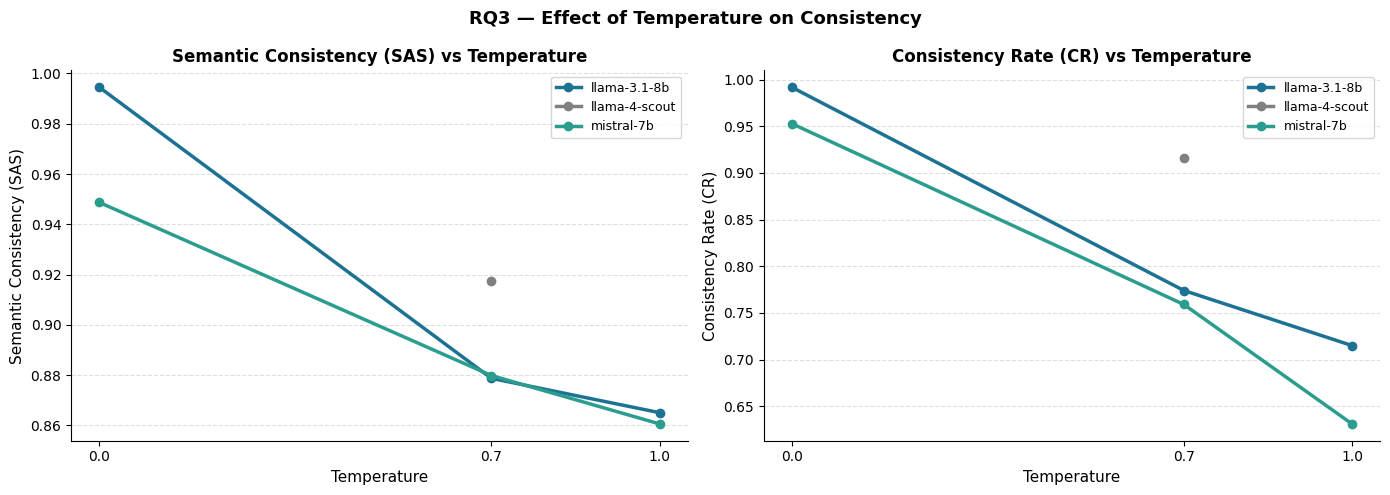

Saved: rq3_temperature_curves.png


In [ ]:
# EXTRA CELL A — Temperature sensitivity curves (line plots)
import matplotlib.pyplot as plt

combined = pd.read_csv("/content/drive/MyDrive/Thesis/rq3_all_temperatures.csv")
combined["temperature"] = combined["temperature"].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
metrics = [("SAS", "Semantic Consistency (SAS)"), ("CR", "Consistency Rate (CR)")]
models  = combined["model"].unique()
colors  = {"llama-3.1-8b": "#1C7293", "mistral-7b": "#2A9D8F", "llama-3.3-70b": "#065A82"}

for ax, (metric, label) in zip(axes, metrics):
    for model in models:
        sub = combined[combined["model"] == model].groupby("temperature")[metric].mean()
        ax.plot(sub.index, sub.values, marker="o", label=model,
                color=colors.get(model, "gray"), linewidth=2.5)
    ax.set_xlabel("Temperature", fontsize=11)
    ax.set_ylabel(label, fontsize=11)
    ax.set_title(f"{label} vs Temperature", fontsize=12, fontweight="bold")
    ax.set_xticks([0.0, 0.7, 1.0])
    ax.legend(fontsize=9)
    ax.spines[["top","right"]].set_visible(False)
    ax.yaxis.grid(True, linestyle="--", alpha=0.4)

plt.suptitle("RQ3 — Effect of Temperature on Consistency", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Thesis/rq3_temperature_curves.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: rq3_temperature_curves.png")

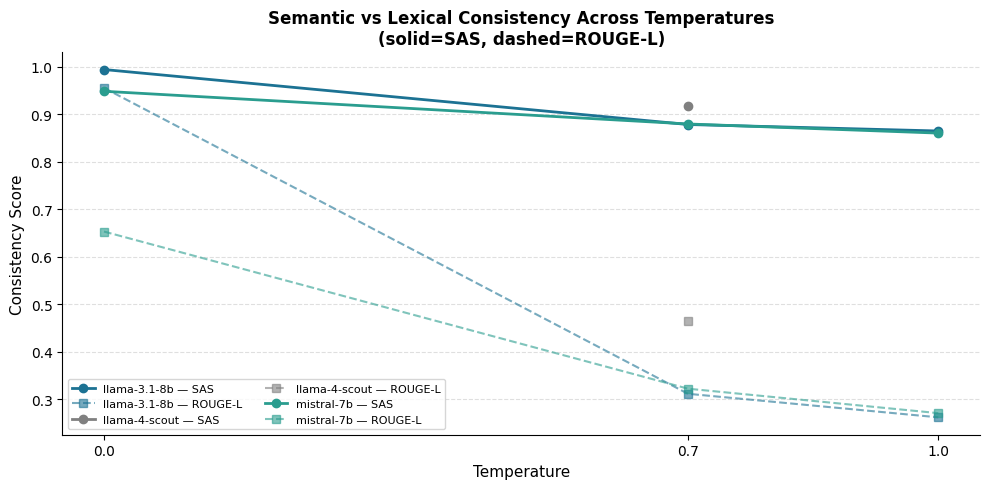

Saved: rq3_semantic_vs_lexical.png


In [ ]:
# EXTRA CELL B — Lexical vs Semantic gap across temperatures (the RQ1 story at scale)
fig, ax = plt.subplots(figsize=(10, 5))

temps = [0.0, 0.7, 1.0]
for model in models:
    sas_vals  = [combined[(combined["model"]==model) & (combined["temperature"]==t)]["SAS"].mean() for t in temps]
    rougevals = [combined[(combined["model"]==model) & (combined["temperature"]==t)]["ROUGE_L"].mean() for t in temps]
    ax.plot(temps, sas_vals,   marker="o", linestyle="-",  color=colors.get(model,"gray"),
            linewidth=2, label=f"{model} — SAS")
    ax.plot(temps, rougevals,  marker="s", linestyle="--", color=colors.get(model,"gray"),
            linewidth=1.5, alpha=0.6, label=f"{model} — ROUGE-L")

ax.set_xlabel("Temperature", fontsize=11)
ax.set_ylabel("Consistency Score", fontsize=11)
ax.set_title("Semantic vs Lexical Consistency Across Temperatures\n(solid=SAS, dashed=ROUGE-L)",
             fontsize=12, fontweight="bold")
ax.set_xticks([0.0, 0.7, 1.0])
ax.legend(fontsize=8, ncol=2)
ax.spines[["top","right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Thesis/rq3_semantic_vs_lexical.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: rq3_semantic_vs_lexical.png")